In [ ]:
# UNION DE DATASETS
import pandas as pd

# 1. Cargar los CSV desde sus carpetas
citas = pd.read_csv('../data/processed/sonrievalencia_citas_final.csv', sep=';')

desplazamientos = pd.read_csv('../data/raw/sonrievalencia_historial_desplazamiento.csv', sep=';')

# 2. Comprobar las dimensiones
print("Dataset de citas:", citas.shape)
print("Dataset de desplazamientos:", desplazamientos.shape)

# 3. Unir los datasets mediante id_cita
df = pd.merge(
    citas,
    desplazamientos.drop(columns='no_acude'),
    on='id_cita',
    how='left',
    validate='one_to_one'
)

# 4. Comprobar el resultado
print("\nDataset unido:", df.shape)
print("Valores nulos:", df.isnull().sum().sum())

# 5. Guardar el nuevo CSV
df.to_csv('sonrievalencia_datos_unidos.csv', sep=';', index=False)

print("\n¡Datasets unidos correctamente!")



Dataset de citas: (2400, 38)
Dataset de desplazamientos: (2400, 13)

Dataset unido: (2400, 49)
Valores nulos: 0

¡Datasets unidos correctamente!


In [ ]:
#--------PARTE 2------------------

# Separar las variables predictoras y el objetivo

X = df.drop(columns=['id_cita', 'no_acude'])
y = df['no_acude']

print("Variables predictoras:", X.shape)
print("Variable objetivo:", y.shape)

Variables predictoras: (2400, 47)
Variable objetivo: (2400,)


In [5]:
from sklearn.feature_selection import VarianceThreshold

# Aplicar el filtro de varianza
selector = VarianceThreshold(threshold=0.01)

X_varianza = selector.fit_transform(X)

# Obtener las variables que se conservan
columnas_conservadas = X.columns[selector.get_support()]

# Obtener las variables eliminadas
columnas_eliminadas = X.columns[~selector.get_support()]

# Crear nuevo DataFrame
X_varianza = pd.DataFrame(
    X_varianza,
    columns=columnas_conservadas,
    index=X.index
)

print("Variables iniciales:", X.shape[1])
print("Variables conservadas:", X_varianza.shape[1])
print("Variables eliminadas:", len(columnas_eliminadas))

print("\nVariables eliminadas:")
print(list(columnas_eliminadas))

Variables iniciales: 47
Variables conservadas: 43
Variables eliminadas: 4

Variables eliminadas:
['tratamiento_Cirugía', 'tratamiento_Férula', 'tratamiento_Sedación', 'tratamiento_Urgencia']


Decisión: eliminación de variables mediante varianza

Se aplicó VarianceThreshold con un umbral de 0,01 para identificar variables con muy poca variabilidad.

Inicialmente teníamos 47 variables predictoras. Se eliminaron 4 variables relacionadas con los tratamientos: tratamiento_Cirugía, tratamiento_Férula, tratamiento_Sedación y tratamiento_Urgencia.

Después del filtrado conservamos 43 variables.

Se tomó esta decisión porque las variables eliminadas presentaban una varianza inferior al umbral establecido y, por tanto, aportaban poca información diferenciadora al conjunto de datos.

In [6]:
# Calcular la matriz de correlación absoluta
correlacion = X_varianza.corr().abs()

# Obtener la parte superior de la matriz para evitar duplicados
import numpy as np

mascara = np.triu(
    np.ones(correlacion.shape),
    k=1
).astype(bool)

correlaciones_superiores = correlacion.where(mascara)

# Buscar pares con correlación igual o superior a 0.90
pares_correlacion = (
    correlaciones_superiores
    .stack()
    .reset_index()
)

pares_correlacion.columns = ['Variable 1', 'Variable 2', 'Correlación']

pares_correlacion = pares_correlacion[
    pares_correlacion['Correlación'] >= 0.90
].sort_values(by='Correlación', ascending=False)

print(pares_correlacion)

        Variable 1   Variable 2  Correlación
1585  distancia_km  distancia_m          1.0


### Decisión: eliminación de variables por correlación

Se calculó la matriz de correlación para identificar variables que aportan información redundante, utilizando un umbral de correlación igual o superior a 0,90.

Se encontró un par de variables con correlación de 1,0: `distancia_km` y `distancia_m`.

Ambas representan la misma distancia, pero utilizan diferentes unidades de medida. Por ello, se decidió conservar `distancia_km` y eliminar `distancia_m`.

Esta decisión permite reducir la redundancia sin perder información.

In [7]:
# Eliminar la variable redundante
X_filtrado = X_varianza.drop(columns=['distancia_m'])

print("Variables después del filtrado:", X_filtrado.shape[1])

Variables después del filtrado: 42


In [8]:
from sklearn.feature_selection import SelectKBest, f_classif, mutual_info_classif

# Método 1: ANOVA
selector_f = SelectKBest(score_func=f_classif, k='all')
selector_f.fit(X_filtrado, y)

ranking_f = pd.DataFrame({
    'Variable': X_filtrado.columns,
    'Puntuacion': selector_f.scores_
}).sort_values(by='Puntuacion', ascending=False)

print("Ranking F_CLASSIF:")
print(ranking_f.head(15))

Ranking F_CLASSIF:
                     Variable  Puntuacion
32          retraso_medio_min  298.156381
33        horas_respuesta_sms  268.575158
35  cancelaciones_previas_pct  267.639589
34   dias_desde_ultima_visita  221.766297
36               distancia_km  135.264436
37        tiempo_trayecto_min  133.570436
38                transbordos  123.787341
4            recordatorio_sms   42.706536
6             dias_antelacion   38.453950
16          seguro_Sin seguro   17.316337
14               seguro_Mutua   11.935113
1                    urgencia   11.756200
2              primera_visita   10.612640
3             visitas_previas    5.417926
29           rango_edad_Joven    4.175252


In [9]:
# Método 2: Mutual Information

selector_mi = SelectKBest(
    score_func=mutual_info_classif,
    k='all'
)

selector_mi.fit(X_filtrado, y)

ranking_mi = pd.DataFrame({
    'Variable': X_filtrado.columns,
    'Puntuacion': selector_mi.scores_
}).sort_values(by='Puntuacion', ascending=False)

print("Ranking MUTUAL INFORMATION:")
print(ranking_mi.head(15))

Ranking MUTUAL INFORMATION:
                     Variable  Puntuacion
33        horas_respuesta_sms    0.069074
35  cancelaciones_previas_pct    0.059463
34   dias_desde_ultima_visita    0.049801
32          retraso_medio_min    0.048267
37        tiempo_trayecto_min    0.032038
36               distancia_km    0.026594
38                transbordos    0.026303
31          rango_edad_Senior    0.020982
13             clinica_Ruzafa    0.018571
22     tratamiento_Extracción    0.017406
15             seguro_Privado    0.014809
6             dias_antelacion    0.014561
29           rango_edad_Joven    0.013199
7             dia_semana_cita    0.008924
28           rango_edad_Menor    0.008781


### Decisión: selección de variables mediante SelectKBest

Se aplicaron dos métodos de selección de variables: `f_classif` y `mutual_info_classif`, para analizar qué características presentan mayor relación con la variable objetivo `no_acude`.

Los dos métodos coincidieron en las siete variables mejor posicionadas:

- retraso_medio_min
- horas_respuesta_sms
- cancelaciones_previas_pct
- dias_desde_ultima_visita
- distancia_km
- tiempo_trayecto_min
- transbordos

Aunque el orden de importancia fue diferente, ambos métodos identificaron las mismas siete variables como las más destacadas.

Por tanto, concluimos que las variables relacionadas con los retrasos, la comunicación con el paciente, las cancelaciones anteriores y los desplazamientos presentan una asociación especialmente relevante con las ausencias.

In [10]:
from sklearn.preprocessing import StandardScaler

# Crear el escalador
scaler = StandardScaler()

# Escalar las variables
X_escalado = scaler.fit_transform(X_filtrado)

print("Dimensiones originales:", X_filtrado.shape)
print("Dimensiones escaladas:", X_escalado.shape)

Dimensiones originales: (2400, 42)
Dimensiones escaladas: (2400, 42)


In [11]:
print("Media de la primera variable:", X_escalado[:, 0].mean())
print("Desviación típica:", X_escalado[:, 0].std())

Media de la primera variable: 3.9968028886505634e-17
Desviación típica: 1.0


### Decisión: escalado de variables

Antes de aplicar PCA, se utilizó `StandardScaler` para estandarizar las 42 variables predictoras.

Esta decisión se tomó porque las variables tienen diferentes unidades y escalas de medida, como kilómetros, minutos, horas y valores binarios.

El escalado permite que ninguna variable tenga más influencia simplemente por presentar valores numéricos más elevados.

Después de aplicar el escalado, se mantuvieron las 2.400 filas y las 42 variables.

In [12]:
from sklearn.decomposition import PCA

# Crear PCA sin limitar el número de componentes
pca = PCA()

# Aplicar PCA a los datos escalados
X_pca = pca.fit_transform(X_escalado)

print("Dimensiones después de PCA:", X_pca.shape)

Dimensiones después de PCA: (2400, 42)


In [13]:
import numpy as np
import pandas as pd

# Varianza explicada por cada componente
varianza = pca.explained_variance_ratio_

# Varianza acumulada
varianza_acumulada = np.cumsum(varianza)

# Crear tabla de resultados
tabla_varianza = pd.DataFrame({
    'Componente': range(1, len(varianza) + 1),
    'Varianza explicada': varianza,
    'Varianza acumulada': varianza_acumulada
})

print(tabla_varianza.head(15))

    Componente  Varianza explicada  Varianza acumulada
0            1            0.086763            0.086763
1            2            0.062658            0.149422
2            3            0.053387            0.202809
3            4            0.049825            0.252634
4            5            0.041566            0.294200
5            6            0.039572            0.333772
6            7            0.036818            0.370590
7            8            0.034223            0.404812
8            9            0.032463            0.437276
9           10            0.032163            0.469439
10          11            0.030309            0.499748
11          12            0.028717            0.528465
12          13            0.028175            0.556640
13          14            0.027407            0.584047
14          15            0.026832            0.610879


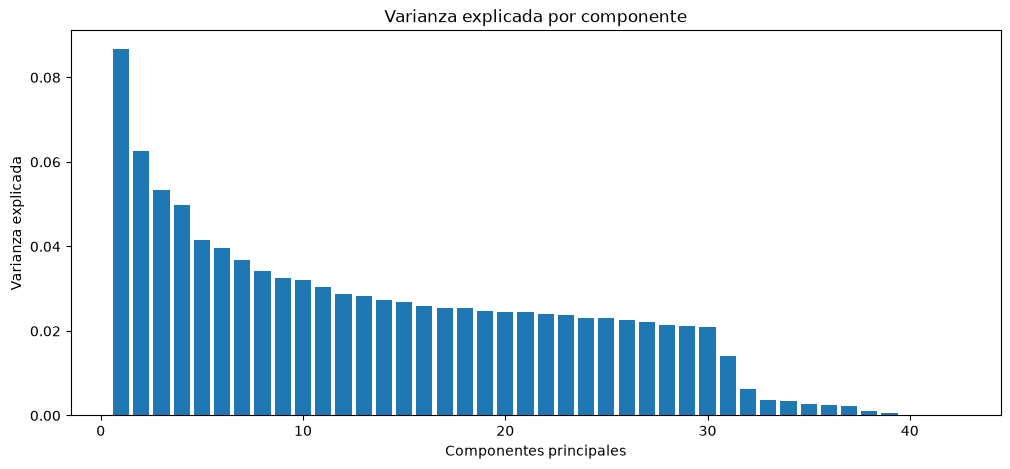

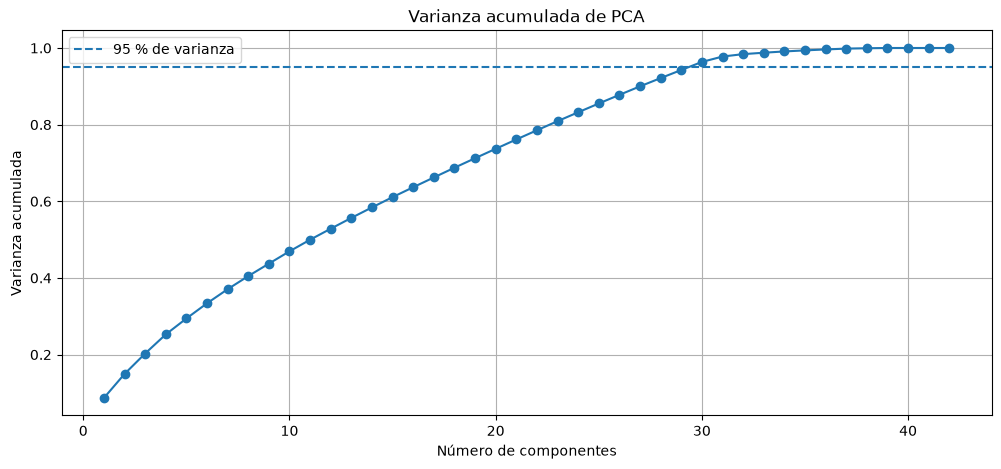

In [15]:
import matplotlib.pyplot as plt

# Gráfico de varianza explicada
plt.figure(figsize=(12, 5))

plt.bar(
    range(1, len(varianza) + 1),
    varianza
)

plt.xlabel('Componentes principales')
plt.ylabel('Varianza explicada')
plt.title('Varianza explicada por componente')
plt.show()


# Gráfico de varianza acumulada
plt.figure(figsize=(12, 5))

plt.plot(
    range(1, len(varianza_acumulada) + 1),
    varianza_acumulada,
    marker='o'
)

plt.axhline(y=0.95, linestyle='--', label='95 % de varianza')

plt.xlabel('Número de componentes')
plt.ylabel('Varianza acumulada')
plt.title('Varianza acumulada de PCA')
plt.legend()
plt.grid()
plt.show()

In [16]:
# Buscar cuántas componentes necesitamos para alcanzar el 95 %
componentes_95 = np.argmax(varianza_acumulada >= 0.95) + 1

print("Componentes necesarias para conservar el 95 %:",
      componentes_95)

print("Varianza acumulada:",
      round(varianza_acumulada[componentes_95 - 1] * 100, 2), "%")

Componentes necesarias para conservar el 95 %: 30
Varianza acumulada: 96.36 %


### Gráfico 1. Varianza explicada por componente

Este gráfico muestra qué porcentaje de la variabilidad de los datos explica cada componente principal.

Se observa que las primeras componentes explican una mayor cantidad de información. A medida que avanzamos, la aportación individual de cada componente va disminuyendo.

Por tanto, las primeras componentes son las que más información concentran.

### Gráfico 2. Varianza acumulada

Este gráfico muestra cómo se va acumulando la información explicada al añadir componentes principales.

La línea discontinua representa el objetivo del 95 % de varianza.

Según los resultados obtenidos, necesitamos 30 componentes para superar ese objetivo, alcanzando un 96,36 % de varianza acumulada.

Esto significa que podemos resumir las 42 variables originales en 30 componentes conservando más del 95 % de su variabilidad.

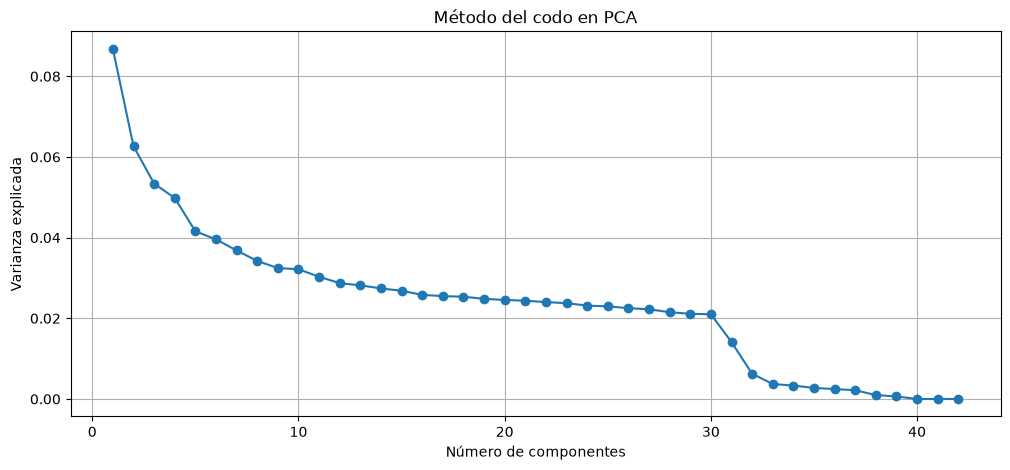

In [17]:
plt.figure(figsize=(12, 5))

plt.plot(
    range(1, len(varianza) + 1),
    varianza,
    marker='o'
)

plt.xlabel('Número de componentes')
plt.ylabel('Varianza explicada')
plt.title('Método del codo en PCA')
plt.grid()
plt.show()

### Selección de componentes mediante el método del codo

Se analizó el gráfico de varianza explicada para identificar el punto a partir del cual añadir nuevas componentes aporta cada vez menos información.

Se observa que la aportación individual de las componentes va disminuyendo progresivamente y que, aproximadamente a partir de la componente 30, la información adicional es muy reducida.

Este criterio visual complementa el criterio del 95 % de varianza acumulada.

In [18]:
# Obtener las cargas de las dos primeras componentes

cargas = pd.DataFrame(
    pca.components_[:2].T,
    index=X_filtrado.columns,
    columns=['PC1', 'PC2']
)

# Mostrar las 10 variables con mayor peso en PC1
print("VARIABLES MÁS IMPORTANTES EN PC1")
print(cargas['PC1'].abs().sort_values(ascending=False).head(10))

# Mostrar las 10 variables con mayor peso en PC2
print("\nVARIABLES MÁS IMPORTANTES EN PC2")
print(cargas['PC2'].abs().sort_values(ascending=False).head(10))

VARIABLES MÁS IMPORTANTES EN PC1
retraso_medio_min            0.493563
horas_respuesta_sms          0.490922
cancelaciones_previas_pct    0.486252
dias_desde_ultima_visita     0.484844
tiempo_trayecto_min          0.109771
distancia_km                 0.105394
transbordos                  0.087898
recordatorio_sms             0.040338
visitas_previas              0.036560
seguro_Sin seguro            0.034243
Name: PC1, dtype: float64

VARIABLES MÁS IMPORTANTES EN PC2
distancia_km                 0.567994
tiempo_trayecto_min          0.566459
transbordos                  0.543502
cancelaciones_previas_pct    0.094456
dias_desde_ultima_visita     0.084342
horas_respuesta_sms          0.083275
retraso_medio_min            0.080232
seguro_Mutua                 0.068174
visitas_previas              0.056921
tratamiento_Revisión         0.055813
Name: PC2, dtype: float64


### Interpretación de PC1 y PC2

Se analizaron las cargas de las dos primeras componentes principales para identificar qué variables tienen mayor influencia en cada una.

**PC1 – Comportamiento e historial del paciente**

Las variables con mayor peso son `retraso_medio_min`, `horas_respuesta_sms`, `cancelaciones_previas_pct` y `dias_desde_ultima_visita`. Por ello, interpretamos esta componente como una representación del comportamiento y del historial del paciente.

**PC2 – Dificultad de desplazamiento**

Las variables con mayor peso son `distancia_km`, `tiempo_trayecto_min` y `transbordos`. Por ello, interpretamos esta componente como una representación de las dificultades que tiene el paciente para desplazarse hasta la clínica.

Estas interpretaciones se basan en las variables con mayor peso absoluto en cada componente.

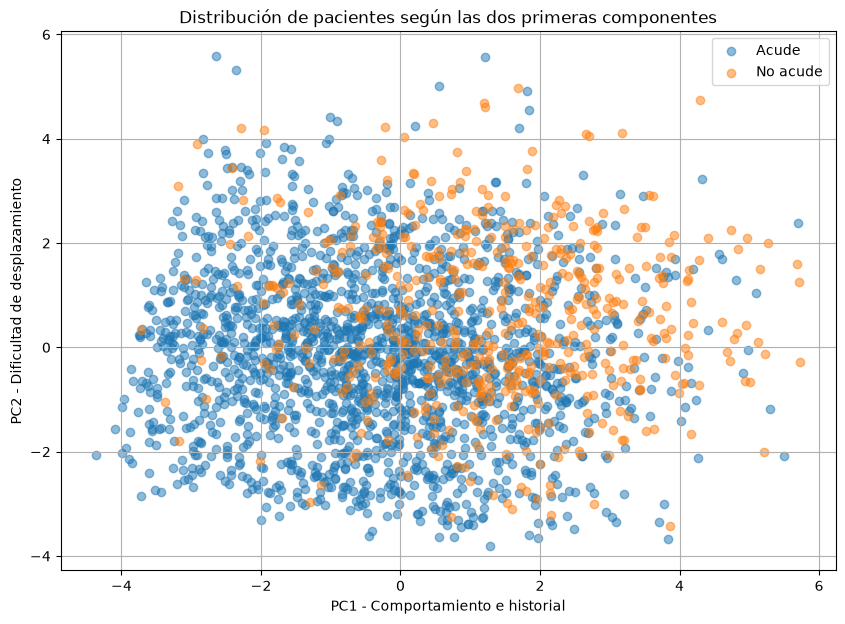

In [19]:
plt.figure(figsize=(10, 7))

plt.scatter(
    X_pca[y == 0, 0],
    X_pca[y == 0, 1],
    label='Acude',
    alpha=0.5
)

plt.scatter(
    X_pca[y == 1, 0],
    X_pca[y == 1, 1],
    label='No acude',
    alpha=0.5
)

plt.xlabel('PC1 - Comportamiento e historial')
plt.ylabel('PC2 - Dificultad de desplazamiento')
plt.title('Distribución de pacientes según las dos primeras componentes')
plt.legend()
plt.grid()
plt.show()

### Distribución de pacientes según PC1 y PC2

Se representaron las dos primeras componentes principales mediante un gráfico de dispersión, diferenciando a los pacientes que acudieron y a los que no acudieron a su cita.

Se observa que ambas clases aparecen bastante mezcladas y no existe una separación clara entre ellas.

Esto indica que las dos primeras componentes, aunque resumen parte de la información del conjunto de datos, no son suficientes por sí solas para distinguir correctamente a los pacientes que faltan a sus citas.

Por tanto, conservar únicamente dos componentes podría provocar una pérdida importante de información predictiva.

# TRABAJO PENDIENTE – CONTINUACIÓN DE LA PRÁCTICA

Los encargos 1, 2 y 3 están realizados. El siguiente paso es completar el Encargo 4 y revisar algunos aspectos pendientes.

## ENCARGO 1 – Unión de datasets
**Estado: COMPLETADO**

- Se unieron los dos CSV mediante `id_cita`.
- Se obtuvieron 2.400 filas y 49 columnas.
- Se comprobó que no existen valores nulos.
- Se guardó el resultado en `sonrievalencia_datos_unidos.csv`.

## ENCARGO 2 – Selección de variables
**Estado: REALIZADO**

Se aplicaron las tres técnicas solicitadas:

- Varianza: se eliminaron 4 variables, pasando de 47 a 43.
- Correlación: se eliminó `distancia_m`, conservando `distancia_km`. Quedaron 42 variables.
- SelectKBest: se realizaron dos rankings mediante `f_classif` y `mutual_info_classif`.

Ambos métodos coincidieron en las siete variables mejor posicionadas.

## ENCARGO 3 – Escalado y PCA
**Estado: REALIZADO, CON ALGUNAS COMPROBACIONES PENDIENTES**

Se realizaron las siguientes tareas:

- Escalado mediante `StandardScaler`.
- Aplicación de PCA.
- Gráfico de varianza explicada.
- Gráfico de varianza acumulada.
- Selección de 30 componentes para conservar un 96,36 % de varianza.
- Análisis del método del codo.
- Interpretación de las cargas de PC1 y PC2.
- Gráfico PC1 frente a PC2 coloreado por `no_acude`.

**Pendiente de revisar:**
- Comparar y justificar el número de componentes obtenido mediante el criterio del 95 % y el método del codo.
- Comprobar el efecto de aplicar PCA sin escalar, tal como pide el profesor.

## ENCARGO 4 – Comparación de modelos
**Estado: PENDIENTE. ES EL SIGUIENTE PASO.**

Hay que entrenar y comparar cuatro modelos utilizando regresión logística:

1. Modelo con todas las variables.
2. Modelo con las variables después del filtrado del Encargo 2.
3. Modelo con PCA y 30 componentes.
4. Modelo con PCA y solamente 2 componentes.

### Requisitos importantes

- Utilizar el mismo modelo de regresión logística en los cuatro casos.
- Realizar una partición de entrenamiento y prueba del 80/20.
- Utilizar `stratify=y`.
- Utilizar `class_weight='balanced'`.
- Incluir `StandardScaler` y PCA dentro de un `Pipeline` cuando corresponda.
- Evitar fugas de información: el escalado y PCA deben aprenderse únicamente con los datos de entrenamiento.
- Evaluar los modelos mediante Recall, F1 y AUC.

### Tabla obligatoria

Completar una tabla comparativa con estos resultados:

| Modelo | Nº variables | Recall | F1 | AUC |
|---|---:|---:|---:|---:|
| Todas las variables | | | | |
| Tras filtrar | | | | |
| PCA, 30 componentes | | | | |
| PCA, 2 componentes | | | | |

Al terminar, escribir una conclusión indicando qué modelo funciona mejor y si realmente compensa utilizar PCA.

## ENTREGA FINAL

- Ejecutar el Notebook completo sin errores.
- Comprobar que todas las decisiones están justificadas en celdas Markdown.
- Completar la tabla de comparación de modelos.
- Incluir los correos enviados a la empresa y sus respuestas.
- Preparar la defensa oral de 10 minutos, incluyendo conclusiones y propuestas de mejora.
- Subir los cambios finales al repositorio de GitHub.